Compare clinical outcomes and mechanism measures across Delphi rounds.


In [1]:
import os, sys, re, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
pd.set_option('display.width', 230)
ORGANIZER_ID = {'P-base': 'gpt120b_default', 'P-base/org-ds': 'deepseekv4_default', 'P-base/org-qwen': 'qwen_default', 'P-base/org-gemini': None, 'P-weak': 'qwen_default', 'P-mixed': 'deepseekv4_default', 'P-strong': 'deepseekv4_default', 'homog gpt': 'gpt120b_e1', 'homog qwen': 'qwen_e1', 'homog deepseekv4': 'deepseekv4_e1', 'homog gemini': 'gemini_e1'}
PANELS8 = ['P-base', 'P-weak', 'P-mixed', 'P-strong', 'homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
ALL11 = PANELS8 + ['P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
SPEC_ALLOWED = {'Cardiology', 'Dermatology', 'Emergency', 'Endocrinology', 'Gastroenterology', 'General Medicine', 'General Surgery', 'Infectious Disease', 'Nephrology', 'Neurology', 'Obstetrics and Gynecology', 'Ophthalmology', 'Orthopedics', 'Other departments', 'Otolaryngology (ENT)', 'Pediatrics', 'Psychiatry', 'Pulmonology', 'Urology'}

def load_run(name):
    d = P.read_csv(P.RAW_RUN[name])
    d = d.dropna(subset=['Vignette']).drop_duplicates('Vignette').set_index('Vignette')
    return d
runs = {n: load_run(n) for n in ALL11}
print({n: (len(d), d.delphi_rounds_executed.value_counts().sort_index().to_dict()) for n, d in runs.items()})


{'P-base': (229, {1.0: 120, 2.0: 62, 3.0: 47}), 'P-weak': (229, {1.0: 119, 2.0: 61, 3.0: 49}), 'P-mixed': (229, {1.0: 142, 2.0: 44, 3.0: 43}), 'P-strong': (229, {1.0: 128, 2.0: 59, 3.0: 42}), 'homog gpt': (229, {1.0: 173, 2.0: 40, 3.0: 16}), 'homog qwen': (229, {1.0: 197, 2.0: 29, 3.0: 3}), 'homog deepseekv4': (229, {1.0: 171, 2.0: 45, 3.0: 13}), 'homog gemini': (229, {1.0: 192, 2.0: 27, 3.0: 10}), 'P-base/org-ds': (229, {1.0: 117, 2.0: 73, 3.0: 39}), 'P-base/org-qwen': (229, {1.0: 116, 2.0: 76, 3.0: 37}), 'P-base/org-gemini': (229, {1.0: 119, 2.0: 83, 3.0: 27})}


In [2]:
def plurality(labels, org_label=None, confs=None):
    lab = [l for l in labels if l]
    if not lab:
        return None
    c = Counter(lab)
    top = max(c.values())
    tied = [k for k, v in c.items() if v == top]
    if len(tied) == 1:
        return tied[0]
    if org_label in tied:
        return org_label
    if confs is not None:
        s = {k: 0.0 for k in tied}
        for l, cf in zip(labels, confs):
            if l in s and pd.notna(cf):
                s[l] += float(cf)
        return max(tied, key=lambda k: s[k])
    return None

def last_round_col(d, r, field, pid):
    return d.get(f'r{int(r)}_{field}__{pid}')

def long_participants(name, field='emergency', truth=None, norm=P.norm_label):
    d = runs[name]
    pids = P.participants(d)
    org = ORGANIZER_ID[name]
    rows = []
    for v, r in d.iterrows():
        R = int(r['delphi_rounds_executed'])
        t = truth(r)
        r1 = [norm(r.get(f'r1_{field}__{p}')) for p in pids]
        conf1 = [r.get(f'r1_confidence__{p}') for p in pids]
        maj1 = plurality(r1, norm(r.get(f'r1_{field}__{org}')) if org else None, conf1)
        cnt = Counter([x for x in r1 if x])
        for p, l1 in zip(pids, r1):
            lf = norm(r.get(f'r{R}_{field}__{p}')) if R > 1 else l1
            rows.append({'panel': name, 'case': v, 'pid': p, 'rounds': R, 'truth': t, 'r1': l1, 'last': lf, 'maj_r1': maj1, 'n_same_r1': cnt.get(l1, 0) if l1 else 0, 'n_labels_r1': len(cnt)})
    return pd.DataFrame(rows)
truth_type = lambda r: P.GT.get(r['Type'])
truth_spec = lambda r: r['Sub Clinical Specialties'] if r['Sub Clinical Specialties'] in SPEC_ALLOWED else None
norm_spec = lambda x: x.strip() if isinstance(x, str) and x.strip() in SPEC_ALLOWED else None


In [3]:
rows = []
for n in ALL11:
    d = runs[n]
    pids = P.participants(d)
    R = d.delphi_rounds_executed.astype(int)
    contested = R >= 2

    def n_distinct(row, rr, field, norm):
        return len({norm(row.get(f'r{rr}_{field}__{p}')) for p in pids} - {None})
    tri_r1 = d.apply(lambda r: n_distinct(r, 1, 'emergency', P.norm_label), axis=1)
    spe_r1 = d.apply(lambda r: n_distinct(r, 1, 'subclinical', norm_spec), axis=1)
    tri_last = d.apply(lambda r: n_distinct(r, int(r.delphi_rounds_executed), 'emergency', P.norm_label), axis=1)
    spe_last = d.apply(lambda r: n_distinct(r, int(r.delphi_rounds_executed), 'subclinical', norm_spec), axis=1)
    rows.append({'panel': n, 'cases': len(d), 'contested': int(contested.sum()), 'share_contested': contested.mean(), 'resolved_R2': int((R == 2).sum()), 'went_R3': int((R == 3).sum()), 'triage_unanimous_R1_in_contested': (tri_r1[contested] == 1).mean(), 'triage_unanimous_last_in_contested': (tri_last[contested] == 1).mean(), 'triage_3way_R1_in_contested': (tri_r1[contested] == 3).mean(), 'triage_3way_last_in_contested': (tri_last[contested] == 3).mean(), 'spec_unanimous_R1_in_contested': (spe_r1[contested] == 1).mean(), 'spec_unanimous_last_in_contested': (spe_last[contested] == 1).mean()})
cons = pd.DataFrame(rows)
display(cons.round(3))
P.save_table(cons, 'round_consensus_changes.csv', index=False)
w = cons[cons.panel.isin(PANELS8)]
for col in ['triage_unanimous_R1_in_contested', 'triage_unanimous_last_in_contested', 'spec_unanimous_R1_in_contested', 'spec_unanimous_last_in_contested']:
    print(f'pooled {col}: {(w[col] * w.contested).sum() / w.contested.sum():.3f}')
tot = cons[cons.panel.isin(PANELS8)]
print('8 main panels: contested cases', tot.contested.sum(), 'of', tot.cases.sum(), '| resolved at R2', tot.resolved_R2.sum(), '| needed R3', tot.went_R3.sum())


,panel,cases,contested,share_contested,resolved_R2,went_R3,triage_unanimous_R1_in_contested,triage_unanimous_last_in_contested,triage_3way_R1_in_contested,triage_3way_last_in_contested,spec_unanimous_R1_in_contested,spec_unanimous_last_in_contested
0,P-base,229,109,0.476,62,47,0.413,0.844,0.0,0.0,0.431,0.826
1,P-weak,229,110,0.480,61,49,0.591,0.918,0.0,0.0,0.255,0.800
2,P-mixed,229,87,0.380,44,43,0.655,0.931,0.0,0.0,0.276,0.713
3,P-strong,229,101,0.441,59,42,0.465,0.931,0.0,0.0,0.327,0.861
4,homog gpt,229,56,0.245,40,16,0.482,0.946,0.0,0.0,0.286,0.929
5,homog qwen,229,32,0.140,29,3,0.625,1.000,0.0,0.0,0.344,1.000
6,homog deepseekv4,229,58,0.253,45,13,0.603,1.000,0.0,0.0,0.241,0.914
7,homog gemini,229,37,0.162,27,10,0.730,1.000,0.0,0.0,0.216,0.946
8,P-base/org-ds,229,112,0.489,73,39,0.420,0.920,0.0,0.0,0.393,0.866
9,P-base/org-qwen,229,113,0.493,76,37,0.416,0.929,0.0,0.0,0.363,0.885


saved tables/round_consensus_changes.csv (11 rows)
pooled triage_unanimous_R1_in_contested: 0.547
pooled triage_unanimous_last_in_contested: 0.929
pooled spec_unanimous_R1_in_contested: 0.307
pooled spec_unanimous_last_in_contested: 0.846
8 main panels: contested cases 590 of 1832 | resolved at R2 367 | needed R3 223


In [4]:
def decision_table(names, field, truth, norm, consensus_col, ord_map=None):
    rows, pooled = ([], [])
    for n in names:
        d = runs[n]
        pids = P.participants(d)
        org = ORGANIZER_ID[n]
        sub = d[d.delphi_rounds_executed.astype(int) >= 2]
        for v, r in sub.iterrows():
            t = truth(r)
            if t is None:
                continue
            r1 = [norm(r.get(f'r1_{field}__{p}')) for p in pids]
            conf = [r.get(f'r1_confidence__{p}') for p in pids]
            m1 = plurality(r1, norm(r.get(f'r1_{field}__{org}')) if org else None, conf)
            fin = norm(r.get(consensus_col))
            split = len(set((x for x in r1 if x)))
            pooled.append({'panel': n, 'case': v, 'truth': t, 'r1_plurality': m1, 'final': fin, 'r1_distinct': split})
    B = pd.DataFrame(pooled)
    B['ok_r1'] = B.r1_plurality == B.truth
    B['ok_fin'] = B.final == B.truth
    if ord_map:
        o = lambda s: s.map(ord_map)
        B['under_r1'] = o(B.r1_plurality) < o(B.truth)
        B['under_fin'] = o(B.final) < o(B.truth)
        B['over_r1'] = o(B.r1_plurality) > o(B.truth)
        B['over_fin'] = o(B.final) > o(B.truth)
    for n, g in B.groupby('panel', sort=False):
        m = P.mcnemar_exact(g.ok_fin, g.ok_r1)
        row = {'panel': n, 'contested_cases': len(g), 'changed_label': int((g.final != g.r1_plurality).sum()), 'acc_r1_plurality': g.ok_r1.mean(), 'acc_final': g.ok_fin.mean(), 'fixed_by_rounds': m['n10'], 'broken_by_rounds': m['n01'], 'p_exact': m['p']}
        if ord_map:
            row.update({'under_r1': g.under_r1.mean(), 'under_fin': g.under_fin.mean(), 'over_r1': g.over_r1.mean(), 'over_fin': g.over_fin.mean()})
        rows.append(row)
    T = pd.DataFrame(rows)
    m = P.mcnemar_exact(B.ok_fin, B.ok_r1)
    allrow = {'panel': 'ALL (pooled panel-cases)', 'contested_cases': len(B), 'changed_label': int((B.final != B.r1_plurality).sum()), 'acc_r1_plurality': B.ok_r1.mean(), 'acc_final': B.ok_fin.mean(), 'fixed_by_rounds': m['n10'], 'broken_by_rounds': m['n01'], 'p_exact': m['p']}
    if ord_map:
        allrow.update({'under_r1': B.under_r1.mean(), 'under_fin': B.under_fin.mean(), 'over_r1': B.over_r1.mean(), 'over_fin': B.over_fin.mean()})
    T = pd.concat([T, pd.DataFrame([allrow])], ignore_index=True)
    return (T, B)
tri_T, tri_B = decision_table(PANELS8, 'emergency', truth_type, P.norm_label, 'delphi_consensus_emergency_type', P.ORD)
print('TRIAGE (8 main panels)')
display(tri_T.round(3))
spe_T, spe_B = decision_table(PANELS8, 'subclinical', truth_spec, norm_spec, 'delphi_consensus_subclinical')
print('SPECIALTY ROUTING (8 main panels)')
display(spe_T.round(3))
P.save_table(tri_T, 'triage_accuracy_final_vs_first_round.csv', index=False)
chg = spe_B[spe_B.final != spe_B.r1_plurality]
print('specialty label changes (R1 plurality -> final), most frequent destinations:')
print(chg.final.value_counts().head(8).to_dict())
print('destination when change broke a correct R1 label:', chg[chg.ok_r1 & ~chg.ok_fin].final.value_counts().head(6).to_dict())
print('reference label in those cases:', chg[chg.ok_r1 & ~chg.ok_fin].truth.value_counts().head(6).to_dict())
P.save_table(spe_T, 'specialty_accuracy_final_vs_first_round.csv', index=False)


TRIAGE (8 main panels)


,panel,contested_cases,changed_label,acc_r1_plurality,acc_final,fixed_by_rounds,broken_by_rounds,p_exact,under_r1,under_fin,over_r1,over_fin
0,P-base,109,14,0.789,0.716,3,11,0.057,0.009,0.028,0.202,0.257
1,P-weak,110,9,0.773,0.764,4,5,1.000,0.009,0.009,0.218,0.227
2,P-mixed,87,10,0.690,0.782,9,1,0.021,0.011,0.011,0.299,0.207
3,P-strong,101,9,0.733,0.782,7,2,0.180,0.030,0.030,0.238,0.188
4,homog gpt,56,18,0.518,0.625,12,6,0.238,0.054,0.054,0.321,0.321
5,homog qwen,32,3,0.688,0.781,3,0,0.250,0.000,0.000,0.312,0.219
6,homog deepseekv4,58,4,0.690,0.690,2,2,1.000,0.034,0.034,0.276,0.276
7,homog gemini,37,1,0.730,0.703,0,1,1.000,0.000,0.000,0.270,0.297
8,ALL (pooled panel-cases),590,68,0.717,0.737,40,28,0.182,0.019,0.022,0.254,0.241


SPECIALTY ROUTING (8 main panels)


,panel,contested_cases,changed_label,acc_r1_plurality,acc_final,fixed_by_rounds,broken_by_rounds,p_exact
0,P-base,108,22,0.630,0.546,5,14,0.064
1,P-weak,109,29,0.587,0.514,7,15,0.134
2,P-mixed,86,19,0.558,0.581,9,7,0.804
3,P-strong,100,21,0.590,0.570,8,10,0.815
4,homog gpt,55,28,0.491,0.545,14,11,0.690
5,homog qwen,32,10,0.500,0.344,1,6,0.125
6,homog deepseekv4,57,17,0.544,0.333,1,13,0.002
7,homog gemini,36,7,0.500,0.389,1,5,0.219
8,ALL (pooled panel-cases),583,153,0.568,0.508,46,81,0.002


saved tables/triage_accuracy_final_vs_first_round.csv (9 rows)
specialty label changes (R1 plurality -> final), most frequent destinations:
{'General Medicine': 54, 'Emergency': 23, 'Pediatrics': 20, 'Infectious Disease': 11, 'Pulmonology': 10, 'Neurology': 8, 'General Surgery': 4, 'Urology': 3}
destination when change broke a correct R1 label: {'General Medicine': 43, 'Pediatrics': 16, 'Emergency': 9, 'Pulmonology': 4, 'Infectious Disease': 2, 'General Surgery': 2}
reference label in those cases: {'Dermatology': 13, 'Infectious Disease': 13, 'Pulmonology': 12, 'Emergency': 9, 'Gastroenterology': 8, 'Urology': 6}
saved tables/specialty_accuracy_final_vs_first_round.csv (9 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\specialty_accuracy_final_vs_first_round.csv'

In [5]:
for lab, B in [('triage', tri_B), ('specialty', spe_B)]:
    print(lab)
    for k, g in B.groupby('r1_distinct'):
        m = P.mcnemar_exact(g.ok_fin, g.ok_r1)
        print(f"   distinct labels at R1 = {k}: n={len(g)} acc R1-plurality {g.ok_r1.mean():.3f} → final {g.ok_fin.mean():.3f}  fixed {m['n10']} broken {m['n01']} p={m['p']:.3g}")


triage
   distinct labels at R1 = 0: n=6 acc R1-plurality 0.000 → final 1.000  fixed 6 broken 0 p=0.0312
   distinct labels at R1 = 1: n=323 acc R1-plurality 0.827 → final 0.833  fixed 4 broken 2 p=0.688
   distinct labels at R1 = 2: n=261 acc R1-plurality 0.598 → final 0.613  fixed 30 broken 26 p=0.689
specialty
   distinct labels at R1 = 0: n=6 acc R1-plurality 0.000 → final 0.667  fixed 4 broken 0 p=0.125
   distinct labels at R1 = 1: n=180 acc R1-plurality 0.783 → final 0.739  fixed 1 broken 9 p=0.0215
   distinct labels at R1 = 2: n=375 acc R1-plurality 0.480 → final 0.405  fixed 39 broken 67 p=0.00842
   distinct labels at R1 = 3: n=22 acc R1-plurality 0.455 → final 0.318  fixed 2 broken 5 p=0.453


In [6]:
tri_T2, _ = decision_table(['P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini'], 'emergency', truth_type, P.norm_label, 'delphi_consensus_emergency_type', P.ORD)
display(tri_T2.round(3))


,panel,contested_cases,changed_label,acc_r1_plurality,acc_final,fixed_by_rounds,broken_by_rounds,p_exact,under_r1,under_fin,over_r1,over_fin
0,P-base/org-ds,112,9,0.768,0.812,7,2,0.180,0.009,0.018,0.223,0.170
1,P-base/org-qwen,113,8,0.805,0.841,6,2,0.289,0.009,0.009,0.186,0.150
2,P-base/org-gemini,110,4,0.800,0.800,2,2,1.000,0.009,0.018,0.191,0.182
3,ALL (pooled panel-cases),335,21,0.791,0.818,15,6,0.078,0.009,0.015,0.200,0.167


In [7]:
rows = []
for n in ALL11:
    org = ORGANIZER_ID[n]
    if org is None:
        continue
    d = runs[n]
    pids = P.participants(d)
    sub = d[d.delphi_rounds_executed.astype(int) >= 2]
    for v, r in sub.iterrows():
        r1 = [P.norm_label(r.get(f'r1_emergency__{p}')) for p in pids]
        conf = [r.get(f'r1_confidence__{p}') for p in pids]
        o1 = P.norm_label(r.get(f'r1_emergency__{org}'))
        m1 = plurality(r1, o1, conf)
        fin = P.norm_label(r.get('delphi_consensus_emergency_type'))
        t = P.GT.get(r['Type'])
        if m1 is None or fin is None or m1 == fin:
            continue
        rows.append({'panel': n, 'toward_organizer_R1': fin == o1, 'organizer_R1_correct': o1 == t, 'fixed': fin == t and m1 != t, 'broken': m1 == t and fin != t})
ST = pd.DataFrame(rows)
print(ST.groupby('panel')[['toward_organizer_R1', 'organizer_R1_correct', 'fixed', 'broken']].agg(['sum', 'size']).iloc[:, ::2])
print("pooled: changes toward the organizer's R1 label:", int(ST.toward_organizer_R1.sum()), 'of', len(ST))
print(pd.crosstab(ST.toward_organizer_R1, [ST.fixed, ST.broken]))
for n in ALL11:
    org = ORGANIZER_ID[n]
    if org is None:
        continue
    d = runs[n]
    acc = (d[f'r1_emergency__{org}'].map(P.norm_label) == d.Type.map(P.GT)).mean()
    print(f'   {n:<18} organizer {org:<20} R1 triage accuracy {acc:.3f}')


                 toward_organizer_R1 organizer_R1_correct fixed broken
                                 sum                  sum   sum    sum
panel                                                                 
P-base                             7                    4     3     11
P-base/org-ds                      3                    5     7      2
P-base/org-qwen                    2                    2     6      2
P-mixed                            4                    5     9      1
P-strong                           2                    4     7      2
P-weak                             5                    2     4      5
homog deepseekv4                   1                    1     2      2
homog gemini                       0                    1     0      1
homog gpt                          4                    8     6      6
homog qwen                         2                    2     3      0
pooled: changes toward the organizer's R1 label: 30 of 79
fixed              

In [8]:
LP = pd.concat([long_participants(n, 'emergency', truth_type) for n in PANELS8], ignore_index=True)
LPc = LP[(LP.rounds >= 2) & LP.truth.notna() & LP.r1.notna() & LP['last'].notna()].copy()
LPc['ok1'], LPc['okL'] = (LPc.r1 == LPc.truth, LPc['last'] == LPc.truth)
rows = []
for n, g in LPc.groupby('panel', sort=False):
    m = P.mcnemar_exact(g.okL, g.ok1)
    rows.append({'panel': n, 'obs': len(g), 'acc_r1': g.ok1.mean(), 'acc_last': g.okL.mean(), 'repaired': m['n10'], 'corrupted': m['n01'], 'p': m['p']})
m = P.mcnemar_exact(LPc.okL, LPc.ok1)
rows.append({'panel': 'ALL', 'obs': len(LPc), 'acc_r1': LPc.ok1.mean(), 'acc_last': LPc.okL.mean(), 'repaired': m['n10'], 'corrupted': m['n01'], 'p': m['p']})
ind = pd.DataFrame(rows)
display(ind.round(3))
P.save_table(ind, 'individual_member_triage_accuracy.csv', index=False)


,panel,obs,acc_r1,acc_last,repaired,corrupted,p
0,P-base,326,0.696,0.736,39,26,0.136
1,P-weak,322,0.717,0.770,32,15,0.019
2,P-mixed,261,0.697,0.774,32,12,0.004
3,P-strong,303,0.686,0.779,45,17,0.000
4,homog gpt,139,0.568,0.590,19,16,0.736
5,homog qwen,96,0.698,0.781,11,3,0.057
6,homog deepseekv4,174,0.707,0.690,12,15,0.701
7,homog gemini,111,0.730,0.703,4,7,0.549
8,ALL,1732,0.692,0.740,194,111,0.000


saved tables/individual_member_triage_accuracy.csv (9 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\individual_member_triage_accuracy.csv'

In [9]:
valid3 = LPc.groupby(['panel', 'case']).r1.transform(lambda s: s.notna().sum()) == 3
INF = LPc[valid3 & (LPc.n_labels_r1 == 2)].copy()
INF['position'] = np.where(INF.n_same_r1 == 2, 'majority', 'minority')
maj_label = INF[INF.n_same_r1 == 2].groupby(['panel', 'case']).r1.first().rename('maj')
INF = INF.join(maj_label, on=['panel', 'case'])
INF = INF[INF.maj.notna()].copy()
INF['maj_correct'] = INF.maj == INF.truth
INF['ends_on_majority'] = INF['last'] == INF.maj
tab = INF.groupby(['position', 'maj_correct']).ends_on_majority.agg(['size', 'mean']).rename(columns={'size': 'obs', 'mean': 'ends_on_majority'})
display(tab.round(3))
mino = INF[INF.position == 'minority']
ct = pd.crosstab(mino.maj_correct, mino.ends_on_majority)
print('minority members: conform when majority right vs wrong →', ct.to_dict(), 'Fisher p =', stats.fisher_exact(ct.values)[1])
majo = INF[INF.position == 'majority']
ct2 = pd.crosstab(majo.maj_correct, majo.ends_on_majority)
print('majority members: stay when majority right vs wrong →', ct2.to_dict(), 'Fisher p =', stats.fisher_exact(ct2.values)[1])
fit = smf.logit('ends_on_majority ~ C(position) * maj_correct', INF.assign(ends_on_majority=INF.ends_on_majority.astype(int), maj_correct=INF.maj_correct.astype(int))).fit(disp=0)
print(fit.summary2().tables[1].round(4))
P.save_table(tab, 'panel_member_influence.csv')


obs  ends_on_majority
position maj_correct                       
majority False        210             0.714
         True         300             0.867
minority False        105             0.667
         True         150             0.813

minority members: conform when majority right vs wrong → {False: {False: 35, True: 28}, True: {False: 70, True: 122}} Fisher p = 0.01176601254482778
majority members: stay when majority right vs wrong → {False: {False: 60, True: 40}, True: {False: 150, True: 260}} Fisher p = 2.526245613932109e-05


                                      Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept                            0.9163    0.1528  5.9985  0.0000  0.6169  1.2157
C(position)[T.minority]             -0.2231    0.2573 -0.8673  0.3858 -0.7274  0.2811
maj_correct                          0.9555    0.2284  4.1830  0.0000  0.5078  1.4032
C(position)[T.minority]:maj_correct -0.1768    0.3728 -0.4744  0.6352 -0.9074  0.5537
saved tables/panel_member_influence.csv (4 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\panel_member_influence.csv'

In [10]:
sw = LPc[LPc.r1 != LPc['last']].copy()
sw['dir'] = np.sign(sw['last'].map(P.ORD) - sw.r1.map(P.ORD))
up, down = (int((sw.dir > 0).sum()), int((sw.dir < 0).sum()))
print(f'label switches: toward more urgency {up}, toward less urgency {down}, binomial p = {stats.binomtest(up, up + down).pvalue:.4f}')
sw['correct_after'] = sw['last'] == sw.truth
print('share of switches that end on the correct label:', round(sw.correct_after.mean(), 3), 'of', len(sw))
print(sw.groupby('dir').correct_after.agg(['size', 'mean']).round(3))


label switches: toward more urgency 125, toward less urgency 183, binomial p = 0.0011
share of switches that end on the correct label: 0.63 of 308
     size   mean
dir             
-1    183  0.918
 1    125  0.208


In [11]:
arms = P.load_main_arms()
stage = {}
for n, (dr, pat) in P.ROUNDS_EVAL.items():
    r1 = P.read_judge(dr + '/llm_as_judge/round_evaluation/' + pat.format(r=1))
    r2 = P.read_judge(dr + '/llm_as_judge/round_evaluation/' + pat.format(r=2))
    stage[n] = (r1, r2, arms[n])

def pen(d):
    return pd.to_numeric(d.judge_penalties, errors='coerce') / pd.to_numeric(d.judge_max, errors='coerce')
rows = []
pool = []
for n, (r1, r2, fin) in stage.items():
    Rn = runs[n].delphi_rounds_executed.astype(int)
    ix = r1.index.intersection(fin.index).intersection(Rn.index)
    for coh, mask in [('contested (R≥2)', Rn.loc[ix] >= 2), ('R=3 only', Rn.loc[ix] == 3)]:
        cix = ix[mask.values]
        a, b = (fin.Judge_score.loc[cix], r1.Judge_score.loc[cix])
        t = P.paired(a, b)
        pa, pb = (pen(fin).loc[cix], pen(r1).loc[cix])
        tp = P.paired(pa, pb)
        rows.append({'panel': n, 'cohort': coh, 'n': len(cix), 'score_r1': b.mean(), 'score_final': a.mean(), 'delta': t['delta'], 'p': t['p_wilcoxon'], 'penalty_r1': pb.mean(), 'penalty_final': pa.mean(), 'p_penalty': tp['p_wilcoxon'], 'cases_with_penalty_r1': float((pb > 0).mean()), 'cases_with_penalty_final': float((pa > 0).mean())})
        if coh == 'contested (R≥2)':
            pool.append(pd.DataFrame({'panel': n, 'case': cix, 'd': (a - b).values, 'dpen': (pa - pb).values, 'pen_r1': (pb > 0).values, 'pen_fin': (pa > 0).values}))
    c3 = ix[(Rn.loc[ix] == 3).values]
    if r2 is not None:
        c3 = c3.intersection(r2.index)
        t = P.paired(fin.Judge_score.loc[c3], r2.Judge_score.loc[c3])
        rows.append({'panel': n, 'cohort': 'R=3: final − round-2 synthesis', 'n': len(c3), 'score_r1': r2.Judge_score.loc[c3].mean(), 'score_final': fin.Judge_score.loc[c3].mean(), 'delta': t['delta'], 'p': t['p_wilcoxon']})
stg = pd.DataFrame(rows)
display(stg.round(4))
P.save_table(stg, 'protocol_quality_by_round_stage.csv', index=False)
PL = pd.concat(pool, ignore_index=True)
print('pooled contested panel-cases:', len(PL), 'Δscore', round(PL.d.mean(), 4), 'p', stats.wilcoxon(PL.d).pvalue, '| Δpenalty share', round(PL.dpen.mean(), 4), 'p', stats.wilcoxon(PL.dpen[PL.dpen != 0]).pvalue if (PL.dpen != 0).any() else None)
ct = pd.crosstab(PL.pen_r1.values, PL.pen_fin.values)
print('cases with ≥1 triggered penalty, R1 synthesis → final synthesis:\n', ct)
b01, b10 = (int(ct.loc[True, False]) if True in ct.index and False in ct.columns else 0, int(ct.loc[False, True]) if False in ct.index and True in ct.columns else 0)
print('penalty removed by rounds:', b01, ' penalty introduced by rounds:', b10, ' exact p:', stats.binomtest(b01, b01 + b10).pvalue)
print('TOST ±0.02 on pooled Δscore:', P.tost_paired(PL.d.values, 0.02), ' ±0.03:', P.tost_paired(PL.d.values, 0.03))


,panel,cohort,n,score_r1,score_final,delta,p,penalty_r1,penalty_final,p_penalty,cases_with_penalty_r1,cases_with_penalty_final
0,P-base,contested (R≥2),109,0.7895,0.8026,0.0131,0.4002,0.0079,0.0027,0.0284,0.0917,0.0550
1,P-base,R=3 only,47,0.7774,0.7824,0.0050,0.8824,0.0073,0.0025,0.1797,0.0851,0.0426
2,P-base,R=3: final − round-2 synthesis,47,0.8190,0.7824,-0.0366,0.0273,NaN,NaN,NaN,NaN,NaN
3,P-weak,contested (R≥2),110,0.7740,0.7698,-0.0042,0.8348,0.0096,0.0108,0.7299,0.1364,0.1545
4,P-weak,R=3 only,49,0.7723,0.7554,-0.0170,0.2579,0.0085,0.0143,0.1730,0.1224,0.2041
5,P-weak,R=3: final − round-2 synthesis,49,0.7487,0.7554,0.0067,0.6026,NaN,NaN,NaN,NaN,NaN
6,P-mixed,contested (R≥2),87,0.7989,0.7815,-0.0174,0.2212,0.0045,0.0065,0.3329,0.0690,0.0920
7,P-mixed,R=3 only,43,0.7892,0.7956,0.0063,0.7916,0.0044,0.0061,0.5002,0.0465,0.0698
8,P-mixed,R=3: final − round-2 synthesis,43,0.7479,0.7956,0.0476,0.0115,NaN,NaN,NaN,NaN,NaN
9,P-strong,contested (R≥2),101,0.7990,0.8070,0.0080,0.4273,0.0032,0.0027,0.7353,0.0495,0.0396


saved tables/protocol_quality_by_round_stage.csv (21 rows)
pooled contested panel-cases: 558 Δscore -0.0003 p 0.8179858822350828 | Δpenalty share -0.0012 p 0.2208889854760514
cases with ≥1 triggered penalty, R1 synthesis → final synthesis:
 col_0  False  True 
row_0              
False    494     19
True      23     22
penalty removed by rounds: 23  penalty introduced by rounds: 19  exact p: 0.6439689563703723
TOST ±0.02 on pooled Δscore: 8.915009359652289e-05  ±0.03: 1.0583958520478827e-08


In [12]:
def axis_contrib(d):
    it = P.items(d)
    mx = it[it.points > 0].groupby('Vignette').points.sum()
    it['signed'] = np.where(it.points > 0, it.points * it.met, -np.abs(it.points) * it.met)
    return it.groupby(['Vignette', 'axis']).signed.sum().unstack(fill_value=0).div(mx, axis=0)
rows = []
for n, (r1, r2, fin) in stage.items():
    Rn = runs[n].delphi_rounds_executed.astype(int)
    A, B0 = (axis_contrib(fin), axis_contrib(r1))
    ix = A.index.intersection(B0.index).intersection(Rn[Rn >= 2].index)
    diffax = A.loc[ix] - B0.loc[ix]
    diffax['panel'] = n
    rows.append(diffax)
AX = pd.concat(rows, ignore_index=True)
res = []
for ax in ['accuracy', 'completeness', 'urgency', 'uncertainty', 'reasoning', 'communication_quality']:
    x = AX[ax].dropna()
    res.append({'axis': ax, 'n': len(x), 'mean_change': x.mean(), 'p': stats.wilcoxon(x[x != 0]).pvalue if (x != 0).sum() > 5 else np.nan})
display(pd.DataFrame(res).round(4))


,axis,n,mean_change,p
0,accuracy,558,-0.0018,0.2792
1,completeness,558,0.0026,0.3399
2,urgency,558,0.0034,0.0536
3,uncertainty,558,-0.0016,0.4735
4,reasoning,558,-0.0012,0.3614
5,communication_quality,558,-0.0017,0.1220


In [13]:
rows = []
single_lab = {m: P.predicted_triage(arms[m]) for m in P.SINGLES}
for n in PANELS8:
    Rn = runs[n].delphi_rounds_executed.astype(int)
    fin = arms[n]
    t = P.true_triage(fin)
    pl = P.predicted_triage(fin)
    for k, idx in [('consensual (R=1)', Rn[Rn == 1].index), ('contested (R≥2)', Rn[Rn >= 2].index)]:
        idx = idx.intersection(fin.index)
        sing_acc = np.nanmean([(single_lab[m].reindex(idx) == t.reindex(idx)).mean() for m in P.SINGLES])
        sing_score = np.nanmean([P.score(arms, m).reindex(idx).mean() for m in P.SINGLES])
        rows.append({'panel': n, 'cohort': k, 'cases': len(idx), 'panel_triage_acc': (pl.reindex(idx) == t.reindex(idx)).mean(), 'panel_score': fin.Judge_score.reindex(idx).mean(), 'mean_single_triage_acc': sing_acc, 'mean_single_score': sing_score})
sig = pd.DataFrame(rows)
display(sig.round(3))
P.save_table(sig, 'round_disagreement_and_quality_signal.csv', index=False)
rows = []
for n in PANELS8:
    Rn = runs[n].delphi_rounds_executed.astype(int)
    fin = arms[n]
    t = P.true_triage(fin)
    pl = P.predicted_triage(fin)
    ix = fin.index.intersection(Rn.index)
    rows.append(pd.DataFrame({'panel': n, 'case': ix, 'err': (pl.loc[ix] != t.loc[ix]).astype(int).values, 'contested': (Rn.loc[ix] >= 2).astype(int).values}))
E = pd.concat(rows)
fitE = smf.logit('err ~ contested + C(panel)', E).fit(disp=0, cov_type='cluster', cov_kwds={'groups': pd.factorize(E.case)[0]})
print('panel triage error ~ contested: OR =', round(np.exp(fitE.params['contested']), 2), 'p =', f"{fitE.pvalues['contested']:.2e}")
rows = []
for n in PANELS8:
    Rn = runs[n].delphi_rounds_executed.astype(int)
    for m in P.SINGLES:
        t = P.true_triage(arms[m])
        pl = single_lab[m]
        ix = arms[m].index.intersection(Rn.index)
        rows.append(pd.DataFrame({'panel': n, 'single': m, 'case': ix, 'err': (pl.loc[ix] != t.loc[ix]).astype(int).values, 'contested': (Rn.loc[ix] >= 2).astype(int).values}))
E2 = pd.concat(rows)
fitE2 = smf.logit('err ~ contested + C(single) + C(panel)', E2).fit(disp=0, cov_type='cluster', cov_kwds={'groups': pd.factorize(E2.case)[0]})
print('single-model triage error on the cases a panel found contested: OR =', round(np.exp(fitE2.params['contested']), 2), 'p =', f"{fitE2.pvalues['contested']:.2e}")


,panel,cohort,cases,panel_triage_acc,panel_score,mean_single_triage_acc,mean_single_score
0,P-base,consensual (R=1),120,0.850,0.778,0.855,0.558
1,P-base,contested (R≥2),109,0.716,0.803,0.817,0.584
2,P-weak,consensual (R=1),119,0.849,0.723,0.862,0.554
3,P-weak,contested (R≥2),110,0.764,0.770,0.809,0.589
4,P-mixed,consensual (R=1),142,0.873,0.789,0.866,0.577
5,P-mixed,contested (R≥2),87,0.782,0.782,0.788,0.560
6,P-strong,consensual (R=1),128,0.859,0.805,0.871,0.573
7,P-strong,contested (R≥2),101,0.782,0.807,0.793,0.568
8,homog gpt,consensual (R=1),173,0.746,0.760,0.838,0.569
9,homog gpt,contested (R≥2),56,0.625,0.756,0.832,0.577


saved tables/round_disagreement_and_quality_signal.csv (16 rows)
panel triage error ~ contested: OR = 1.86 p = 6.53e-04


single-model triage error on the cases a panel found contested: OR = 1.5 p = 1.06e-02


In [14]:
def parse_json(s):
    if not isinstance(s, str):
        return None
    try:
        return json.loads(s)
    except Exception:
        m = re.search('\\{.*\\}', s, re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except Exception:
                return None
    return None
rows = []
for n in PANELS8:
    d = runs[n]
    pids = P.participants(d)
    for v, r in d.iterrows():
        R = int(r.delphi_rounds_executed)
        for p in pids:
            for rr in (2, 3):
                if R < rr:
                    continue
                js = parse_json(r.get(f'r{rr}_raw__{p}'))
                if not js:
                    continue
                ans = js.get('answers') or []
                ch = sum((bool(a.get('changed_from_previous')) for a in ans if isinstance(a, dict)))
                rec = {'panel': n, 'case': v, 'pid': p, 'round': rr, 'answers': len(ans), 'changed': ch}
                if rr == 2:
                    rec['insufficient'] = not bool(js.get('is_questionnaire_sufficient', True))
                    rec['missing_aspects'] = len(js.get('missing_aspects') or [])
                if rr == 3:
                    oa = js.get('outliers_addressed') or []
                    rec['outliers_reviewed'] = len(oa)
                    rec['outliers_updated_view'] = sum((bool(o.get('updated_my_view')) for o in oa if isinstance(o, dict)))
                rows.append(rec)
F = pd.DataFrame(rows)
F['share_changed'] = F.changed / F.answers.replace(0, np.nan)
print('answers revised per round (share of unified questions marked changed):')
print(F.groupby('round').share_changed.describe().round(3))
print('round 2: questionnaire judged insufficient by the expert:', round(F[F['round'] == 2].insufficient.mean(), 3), '| mean missing aspects listed:', round(F[F['round'] == 2].missing_aspects.mean(), 2))
r3 = F[F['round'] == 3]
print('round 3: outlier positions reviewed per expert:', round(r3.outliers_reviewed.mean(), 2), "| share of reviews that updated the expert's view:", round(r3.outliers_updated_view.sum() / r3.outliers_reviewed.sum(), 3))
add = []
for n in PANELS8:
    d = runs[n]
    for v, r in d[d.delphi_rounds_executed.astype(int) == 3].iterrows():
        js = parse_json(r.get('organizer_after_r2_raw'))
        if js:
            add.append(len(js.get('added_questions') or []))
print('round-3 questionnaires with organizer-added questions:', round(np.mean(np.array(add) > 0), 3), 'of', len(add))
P.save_table(F.groupby(['panel', 'round'])[['share_changed']].mean(), 'round_answer_revisions.csv')


answers revised per round (share of unified questions marked changed):
        count   mean    std  min  25%  50%  75%  max
round                                               
2      1579.0  0.043  0.118  0.0  0.0  0.0  0.0  1.0
3       658.0  0.028  0.104  0.0  0.0  0.0  0.0  1.0
round 2: questionnaire judged insufficient by the expert: 0.207 | mean missing aspects listed: 0.95
round 3: outlier positions reviewed per expert: 1.18 | share of reviews that updated the expert's view: 0.205
round-3 questionnaires with organizer-added questions: 0.158 of 221
saved tables/round_answer_revisions.csv (16 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\round_answer_revisions.csv'

In [15]:
lab = LPc.set_index(['panel', 'case', 'pid'])
rev2 = F[F['round'] == 2].set_index(['panel', 'case', 'pid'])['share_changed']
J = lab.join(rev2.rename('rev2'), how='inner')
J['label_changed'] = J.r1 != J['last']
print('share of experts who changed their triage label, by any content revision in R2:')
print(J.groupby(J.rev2 > 0).label_changed.agg(['size', 'mean']).round(3))


share of experts who changed their triage label, by any content revision in R2:
       size   mean
rev2              
False  1421  0.165
True    311  0.238


In [16]:
MQ = {'AC (gpt·qwen3-235b·deepseek-v4)': ('experiments/external_benchmarks/medmcqa/panel_gpt120_organizer_qwen_deepseek/delphi_medmcqa_noroles.csv', 'gpt120b_default'), 'Optimum (gpt·qwen3-235b·qwen3.6-35b)': ('experiments/external_benchmarks/initial_runs/heterogeneous_gpt120_organizer/delphi_medmcqa_noroles.csv', 'gpt120b_default'), 'AC-Alice (gpt·qwen3-235b·alice)': ('experiments/external_benchmarks/initial_runs/panel_gpt120_organizer_qwen_alice/delphi_medmcqa_noroles.csv', 'gpt120b_default'), 'DeepSeek trio (deepseek-v4 ×3)': ('experiments/external_benchmarks/initial_runs/three_deepseek_members/delphi_medmcqa_noroles.csv', 'deepseekv4_default')}

def normopt(x):
    if not isinstance(x, str):
        return None
    x = x.strip().upper()[:1]
    return x if x in 'ABCD' else None
rows, pooled_ind, pooledB = ([], [], [])
for name, (path, org) in MQ.items():
    d = P.read_csv(path)
    d = d[d.case_id.notna()].drop_duplicates('case_id').set_index('case_id')
    pids = sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_selected_option__')))
    R = pd.to_numeric(d.delphi_rounds_executed, errors='coerce').fillna(1).astype(int)
    t = d.correct_option_letter.map(normopt)
    fin = d.delphi_consensus_selected_option.map(normopt)
    recs = []
    for v, r in d.iterrows():
        r1 = [normopt(r.get(f'r1_selected_option__{p}')) for p in pids]
        conf = [r.get(f'r1_confidence__{p}') for p in pids]
        m1 = plurality(r1, normopt(r.get(f'r1_selected_option__{org}')), conf)
        recs.append((v, m1, len(set((x for x in r1 if x)))))
        Rv = int(R.loc[v])
        for p, l1 in zip(pids, r1):
            lf = normopt(r.get(f'r{Rv}_selected_option__{p}')) if Rv > 1 else l1
            pooled_ind.append({'panel': name, 'case': v, 'rounds': Rv, 'truth': t.loc[v], 'r1': l1, 'last': lf})
    M1 = pd.DataFrame(recs, columns=['case', 'r1_plurality', 'r1_distinct']).set_index('case')
    contested = R >= 2
    ix = d.index[contested.values]
    ok1, okf = (M1.r1_plurality.loc[ix] == t.loc[ix], fin.loc[ix] == t.loc[ix])
    m = P.mcnemar_exact(okf, ok1)
    rows.append({'panel': name, 'questions': len(d), 'contested': int(contested.sum()), 'acc_all_final': float((fin == t).mean()), 'acc_contested_r1_plurality': ok1.mean(), 'acc_contested_final': okf.mean(), 'fixed_by_rounds': m['n10'], 'broken_by_rounds': m['n01'], 'p_exact': m['p']})
    pooledB.append(pd.DataFrame({'ok1': ok1.values, 'okf': okf.values}))
MB = pd.DataFrame(rows)
PBq = pd.concat(pooledB)
m = P.mcnemar_exact(PBq.okf, PBq.ok1)
MB = pd.concat([MB, pd.DataFrame([{'panel': 'ALL', 'contested': len(PBq), 'acc_contested_r1_plurality': PBq.ok1.mean(), 'acc_contested_final': PBq.okf.mean(), 'fixed_by_rounds': m['n10'], 'broken_by_rounds': m['n01'], 'p_exact': m['p']}])], ignore_index=True)
display(MB.round(4))
P.save_table(MB, 'medmcqa_accuracy_by_round.csv', index=False)
MI = pd.DataFrame(pooled_ind)
MIc = MI[(MI.rounds >= 2) & MI.r1.notna() & MI['last'].notna()]
m = P.mcnemar_exact(MIc['last'] == MIc.truth, MIc.r1 == MIc.truth)
print(f"MedMCQA individual experts in contested questions: acc R1 {(MIc.r1 == MIc.truth).mean():.3f} → last {(MIc['last'] == MIc.truth).mean():.3f}; repaired {m['n10']} corrupted {m['n01']} p={m['p']:.2e}")
rows = []
for (pn, cs), g in MIc.groupby(['panel', 'case']):
    c = Counter(g.r1)
    if len(c) != 2 or max(c.values()) != 2:
        continue
    maj = max(c, key=c.get)
    for _, r in g.iterrows():
        rows.append({'position': 'majority' if r.r1 == maj else 'minority', 'maj_correct': maj == r.truth, 'ends_on_majority': r['last'] == maj})
MC = pd.DataFrame(rows)
display(MC.groupby(['position', 'maj_correct']).ends_on_majority.agg(['size', 'mean']).round(3))


,panel,questions,contested,acc_all_final,acc_contested_r1_plurality,acc_contested_final,fixed_by_rounds,broken_by_rounds,p_exact
0,AC (gpt·qwen3-235b·deepseek-v4),1000.0,173,0.881,0.5954,0.6590,20,9,0.0614
1,Optimum (gpt·qwen3-235b·qwen3.6-35b),1000.0,179,0.876,0.5922,0.6536,17,6,0.0347
2,AC-Alice (gpt·qwen3-235b·alice),1000.0,199,0.862,0.5176,0.5729,24,13,0.0989
3,DeepSeek trio (deepseek-v4 ×3),1000.0,82,0.893,0.3293,0.6098,29,6,0.0001
4,ALL,NaN,633,NaN,0.5355,0.6240,90,34,0.0000


saved tables/medmcqa_accuracy_by_round.csv (5 rows)
MedMCQA individual experts in contested questions: acc R1 0.489 → last 0.635; repaired 401 corrupted 157 p=1.32e-25


size   mean
position maj_correct             
majority False         320  0.750
         True          576  0.943
minority False         160  0.700
         True          288  0.896

In [17]:
ex = {}
for k in ['optimum_early_stop', 'rounds_no_early_stop']:
    j = P.read_judge(f'experiments/panel_parameter_sweeps/rounds/llm_as_judge/delphi_{k}_judge.csv')
    raw = P.read_csv(f'experiments/panel_parameter_sweeps/rounds/delphi_{k}.csv').dropna(subset=['Vignette']).drop_duplicates('Vignette').set_index('Vignette')
    ex[k] = (j, raw)
a, b = (ex['rounds_no_early_stop'][0], ex['optimum_early_stop'][0])
t = P.paired(a.Judge_score, b.Judge_score)
ix = a.index.intersection(b.index)
dvec = (a.Judge_score.loc[ix] - b.Judge_score.loc[ix]).values
print('rubric: forced 3 rounds − adaptive:', round(t['delta'], 4), 'p =', round(t['p_wilcoxon'], 3), 'TOST±0.05 p =', round(P.tost_paired(dvec, 0.05), 4))
for k, (j, raw) in ex.items():
    tot = sum((pd.to_numeric(raw[c], errors='coerce').fillna(0) for c in raw.columns if re.match('r[123]_total_tokens__', c) or c in ('organizer_after_r1_total_tokens', 'organizer_after_r2_total_tokens', 'final_synthesis_total_tokens')))
    acc = (P.predicted_triage(j) == P.true_triage(j)).mean()
    print(f'{k:<24} score {j.Judge_score.mean():.4f}  triage acc {acc:.3f}  mean rounds {raw.delphi_rounds_executed.mean():.2f}  tokens/case {tot.mean():.0f}')
raw = ex['rounds_no_early_stop'][1]
pids = P.participants(raw)
un = raw.apply(lambda r: len({P.norm_label(r.get(f'r1_emergency__{p}')) for p in pids} - {None}) == 1, axis=1)
fin = raw.delphi_consensus_emergency_type.map(P.norm_label)
r1maj = raw.apply(lambda r: plurality([P.norm_label(r.get(f'r1_emergency__{p}')) for p in pids], P.norm_label(r.get('r1_emergency__gpt120b_default'))), axis=1)
t = raw.Type.map(P.GT)
for lab, msk in [('unanimous after R1', un), ('split after R1', ~un)]:
    print(f'forced-rounds run, {lab}: n={int(msk.sum())} changed label {(fin[msk] != r1maj[msk]).sum()} acc R1-plurality {(r1maj[msk] == t[msk]).mean():.3f} → final {(fin[msk] == t[msk]).mean():.3f}')


rubric: forced 3 rounds − adaptive: 0.0064 p = 0.894 TOST±0.05 p = 0.0052
optimum_early_stop       score 0.8194  triage acc 0.817  mean rounds 1.70  tokens/case 26052
rounds_no_early_stop     score 0.8258  triage acc 0.783  mean rounds 3.00  tokens/case 44438
forced-rounds run, unanimous after R1: n=45 changed label 0 acc R1-plurality 0.844 → final 0.844
forced-rounds run, split after R1: n=15 changed label 2 acc R1-plurality 0.600 → final 0.600


In [18]:
rows = []
for n in PANELS8:
    d = runs[n]

    def s(cols):
        return sum((pd.to_numeric(d[c], errors='coerce').fillna(0) for c in cols)) if cols else 0
    r23 = s([c for c in d.columns if re.match('r[23]_total_tokens__', c)] + ['organizer_after_r2_total_tokens'])
    allt = s([c for c in d.columns if re.match('r[123]_total_tokens__', c)] + [c for c in ('organizer_after_r1_total_tokens', 'organizer_after_r2_total_tokens', 'final_synthesis_total_tokens') if c in d.columns])
    rows.append({'panel': n, 'tokens_per_case': allt.mean(), 'share_spent_in_rounds_2_3': r23.sum() / allt.sum() if allt.sum() else np.nan})
cost = pd.DataFrame(rows)
display(cost.round(3))
P.save_table(cost, 'delphi_round_token_costs.csv', index=False)


,panel,tokens_per_case,share_spent_in_rounds_2_3
0,P-base,26746.454,0.311
1,P-weak,24400.328,0.342
2,P-mixed,22758.031,0.220
3,P-strong,23692.790,0.239
4,homog gpt,20959.755,0.168
5,homog qwen,337.812,0.000
6,homog deepseekv4,23911.528,0.133
7,homog gemini,12681.424,0.115


saved tables/delphi_round_token_costs.csv (8 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\delphi_round_token_costs.csv'

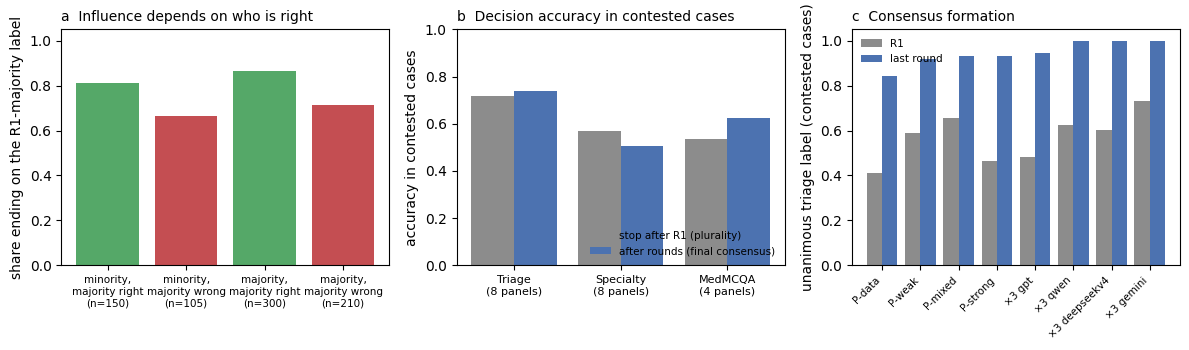

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
g = tab.reset_index()
lab = {('minority', True): 'minority,\nmajority right', ('minority', False): 'minority,\nmajority wrong', ('majority', True): 'majority,\nmajority right', ('majority', False): 'majority,\nmajority wrong'}
order = [('minority', True), ('minority', False), ('majority', True), ('majority', False)]
vals = [g[(g.position == p) & (g.maj_correct == c)].ends_on_majority.iloc[0] for p, c in order]
ns = [g[(g.position == p) & (g.maj_correct == c)].obs.iloc[0] for p, c in order]
axs[0].bar(range(4), vals, color=['#55A868', '#C44E52', '#55A868', '#C44E52'])
axs[0].set_xticks(range(4))
axs[0].set_xticklabels([lab[o] + f'\n(n={k})' for o, k in zip(order, ns)], fontsize=7.5)
axs[0].set_ylabel('share ending on the R1-majority label')
axs[0].set_ylim(0, 1.05)
axs[0].set_title('a  Influence depends on who is right', loc='left', fontsize=10)
lbls = ['Triage\n(8 panels)', 'Specialty\n(8 panels)', 'MedMCQA\n(4 panels)']
r1v = [tri_T.iloc[-1].acc_r1_plurality, spe_T.iloc[-1].acc_r1_plurality, MB.iloc[-1].acc_contested_r1_plurality]
fv = [tri_T.iloc[-1].acc_final, spe_T.iloc[-1].acc_final, MB.iloc[-1].acc_contested_final]
x = np.arange(3)
axs[1].bar(x - 0.2, r1v, 0.4, label='stop after R1 (plurality)', color='#8C8C8C')
axs[1].bar(x + 0.2, fv, 0.4, label='after rounds (final consensus)', color='#4C72B0')
axs[1].set_xticks(x)
axs[1].set_xticklabels(lbls, fontsize=8)
axs[1].set_ylim(0, 1)
axs[1].set_ylabel('accuracy in contested cases')
axs[1].legend(frameon=False, fontsize=7.5, loc='lower right')
axs[1].set_title('b  Decision accuracy in contested cases', loc='left', fontsize=10)
c8 = cons[cons.panel.isin(PANELS8)]
axs[2].bar(np.arange(len(c8)) - 0.2, c8.triage_unanimous_R1_in_contested, 0.4, color='#8C8C8C', label='R1')
axs[2].bar(np.arange(len(c8)) + 0.2, c8.triage_unanimous_last_in_contested, 0.4, color='#4C72B0', label='last round')
axs[2].set_xticks(range(len(c8)))
axs[2].set_xticklabels([p.replace('homog ', '×3 ') for p in c8.panel], rotation=45, ha='right', fontsize=7.5)
axs[2].set_ylabel('unanimous triage label (contested cases)')
axs[2].legend(frameon=False, fontsize=7.5)
axs[2].set_title('c  Consensus formation', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(P.path_join(P.FIGURES, 'S_NB04_rounds.png'), dpi=220)
